# Business Understanding

**Latar Belakang :**

Sebuah institusi perbankan mengalami kendala efisiensi dalam menjalankan kampanye pemasaran untuk menawarkan deposito berjangka kepada nasabah. di mana menghubungi seluruh
database nasabah secara acak akan banyak sekali membuang resource dan sangat tidak efisien.

**Tujuan :**     



*   Membangun model KNN dengan memanfaatkan data hisotris nasabah untuk mengklasifikasi apakah nasabah akan berlangganan deposito



**Masalah :**


*  Menghubungi semua nasabah sangat tidak efisien





**Solusi :**



*   Membuat sebuah model knn untuk secara efisien mengklasifikasi mana yang mau mproduk deposito mana yang tidak.


Deskripsi Kolom:

1. age (Usia): Umur nasabah dalam tahun (Fitur Numerik).
2. job (Pekerjaan): Jenis pekerjaan nasabah (Fitur Kategorikal: management,
technician, entrepreneur, blue-collar, dll.).
3. marital (Status Pernikahan): Status perkawinan nasabah (Fitur Kategorikal:
married, single, divorced).
4. education (Tingkat Pendidikan): Jenjang pendidikan terakhir nasabah (Fitur
Kategorikal: primary, secondary, tertiary, unknown).
5. default (Riwayat Kredit Macet): Apakah nasabah memiliki kredit macet (Fitur
Kategorikal: yes, no).
6. balance (Saldo Rekening): Rata-rata saldo tahunan nasabah dalam rekening (Fitur
Numerik).
7. housing (Cicilan Perumahan): Apakah nasabah memiliki cicilan KPR/rumah (Fitur
Kategorikal: yes, no).
8. loan (Pinjaman Pribadi): Apakah nasabah memiliki pinjaman pribadi (Fitur
Kategorikal: yes, no).

9. duration (Durasi Kontak Terakhir): Durasi panggilan telepon terakhir dalam detik
(Fitur Numerik).
10. campaign (Jumlah Kontak Kampanye): Berapa kali nasabah dihubungi selama
kampanye ini (Fitur Numerik).
11. y (Variabel Target / Label): Keputusan nasabah berlangganan deposito berjangka
(yes atau no).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import ttk, messagebox
import os
from collections import Counter

In [2]:
df = pd.read_csv('dataset/Assignment-2_Data.csv')

In [3]:
df.head()


,Id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1001,999.0,management,married,tertiary,no,2143.0,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,1002,44.0,technician,single,secondary,no,29.0,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,1003,33.0,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,1004,47.0,blue-collar,married,unknown,no,1506.0,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,1005,33.0,unknown,single,unknown,no,1.0,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.size

813798

In [5]:
df.shape

(45211, 18)

## EDA

In [6]:
df.describe()

,Id,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45202.000000,45208.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,23606.000000,40.954714,1362.346620,15.806419,258.163080,2.763841,40.197828,0.580323
std,13051.435847,11.539144,3044.852387,8.322476,257.527812,3.098021,100.128746,2.303441
min,1001.000000,-1.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,12303.500000,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,23606.000000,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,34908.500000,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,46211.000000,999.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Id         45211 non-null  int64  
 1   age        45202 non-null  float64
 2   job        45211 non-null  str    
 3   marital    45211 non-null  str    
 4   education  45211 non-null  str    
 5   default    45211 non-null  str    
 6   balance    45208 non-null  float64
 7   housing    45211 non-null  str    
 8   loan       45211 non-null  str    
 9   contact    45211 non-null  str    
 10  day        45211 non-null  int64  
 11  month      45211 non-null  str    
 12  duration   45211 non-null  int64  
 13  campaign   45211 non-null  int64  
 14  pdays      45211 non-null  int64  
 15  previous   45211 non-null  int64  
 16  poutcome   45211 non-null  str    
 17  y          45211 non-null  str    
dtypes: float64(2), int64(6), str(10)
memory usage: 6.2 MB


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isna().sum()

Id           0
age          9
job          0
marital      0
education    0
default      0
balance      3
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [10]:
df.dropna(inplace=True)

In [11]:
df = df[df['age'] <= 100]

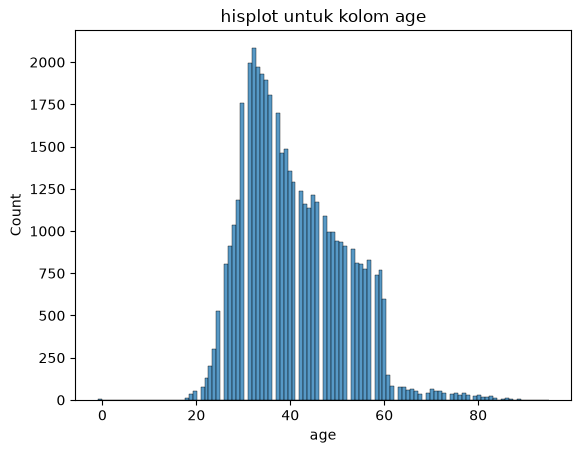

In [12]:
sns.histplot(df['age'])
plt.title("hisplot untuk kolom age")
plt.show()

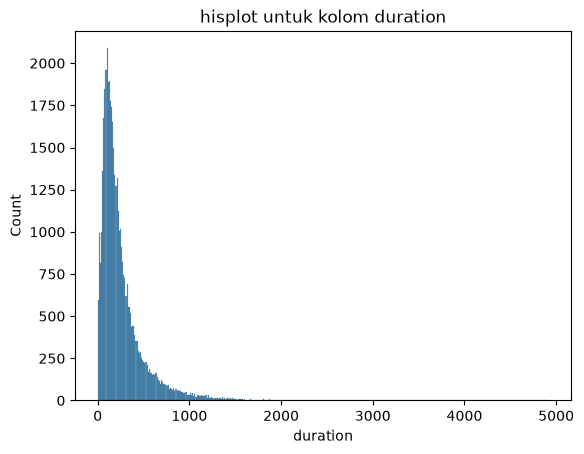

In [13]:
sns.histplot(df['duration'])
plt.title("hisplot untuk kolom duration")
plt.show()

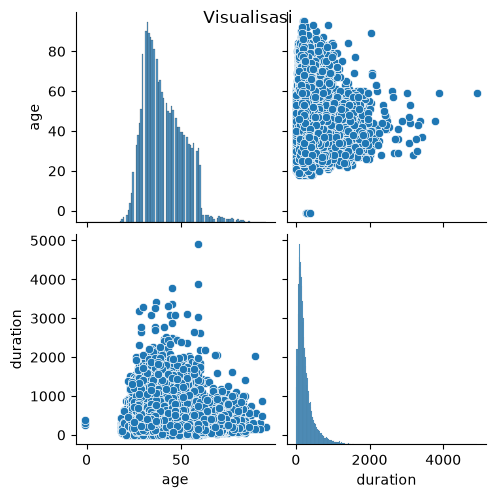

In [14]:
g = sns.pairplot(df, vars=['age','duration'])
g.fig.suptitle("Visualisasi")
plt.show()

## Data preprocessing

Membersihkan dan mengkonversi data yang bertipe str atau kategorikal menjadi numerik

In [15]:
df['marital'] = df['marital'].map({'single' : 0, 'married' : 1, 'divorced' : 2})
df['housing'] = df['housing'].map({'no' : 0, 'yes' : 1})
df['loan'] = df['loan'].map({'no' : 0, 'yes' : 1})
df['default'] = df['default'].map({'no' : 0, 'yes' : 1})
df['job'] = df['job'].astype(str).str.replace('.', '', regex=False)
df['job'] = pd.factorize(df['job'])[0]
df['education'] = df['education'].map({'primary': 0, 'secondary': 1, 'tertiary': 2, 'unknown': 3})

In [16]:
df.head(8)

,Id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
1,1002,44.0,0,0,1,0,29.0,1,0,unknown,5,may,151,1,-1,0,unknown,no
2,1003,33.0,1,1,1,0,2.0,1,1,unknown,5,may,76,1,-1,0,unknown,no
3,1004,47.0,2,1,3,0,1506.0,1,0,unknown,5,may,92,1,-1,0,unknown,no
4,1005,33.0,3,0,3,0,1.0,0,0,unknown,5,may,198,1,-1,0,unknown,no
5,1006,35.0,4,1,2,0,231.0,1,0,unknown,5,may,139,1,-1,0,unknown,no
6,1007,28.0,4,0,2,0,447.0,1,1,unknown,5,may,217,1,-1,0,unknown,no
10,1011,41.0,5,2,1,0,270.0,1,0,unknown,5,may,222,1,-1,0,unknown,no
11,1012,29.0,5,0,1,0,390.0,1,0,unknown,5,may,137,1,-1,0,unknown,no


Mengecek Outlier

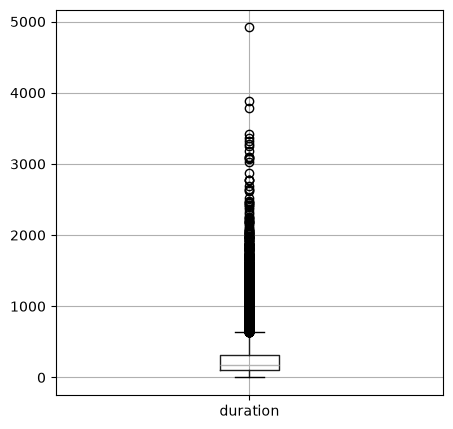

In [17]:
plt.figure(figsize=[5,5])
df.boxplot(column=['duration'])
plt.show()

<Axes: >

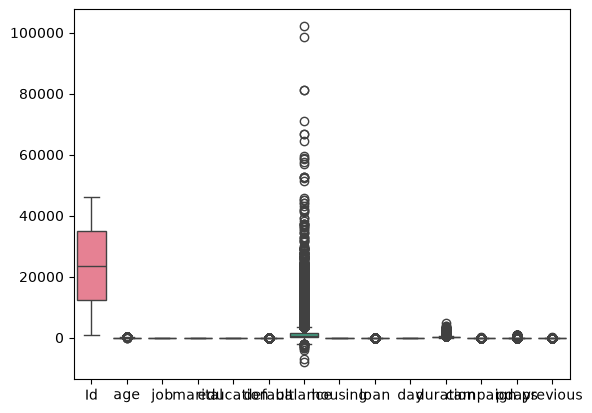

In [18]:
sns.boxplot(df)

In [19]:

cols = df.select_dtypes(include=[np.number]).columns.drop('Id', errors='ignore')
Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
outlier = ((df[cols] < batas_bawah) | (df[cols] > batas_atas)).sum()
print("Jumlah outlier per kolom:")
print(outlier[outlier > 0])

Jumlah outlier per kolom:
age          489
default      814
balance     4729
loan        7242
duration    3233
campaign    3064
pdays       8257
previous    8257
dtype: int64


In [20]:
kolom = ['age', 'balance', 'duration', 'campaign']
for col in kolom:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    bb = q1 - 1.5 * iqr
    ba = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower=bb, upper=ba)


In [21]:
X = df.drop(columns=['Id', 'contact', 'month', 'poutcome', 'y', 'job','day'])
y = df['y'].map({'no': 0, 'yes': 1})

Mengecek Korelasi data dengan heatmap

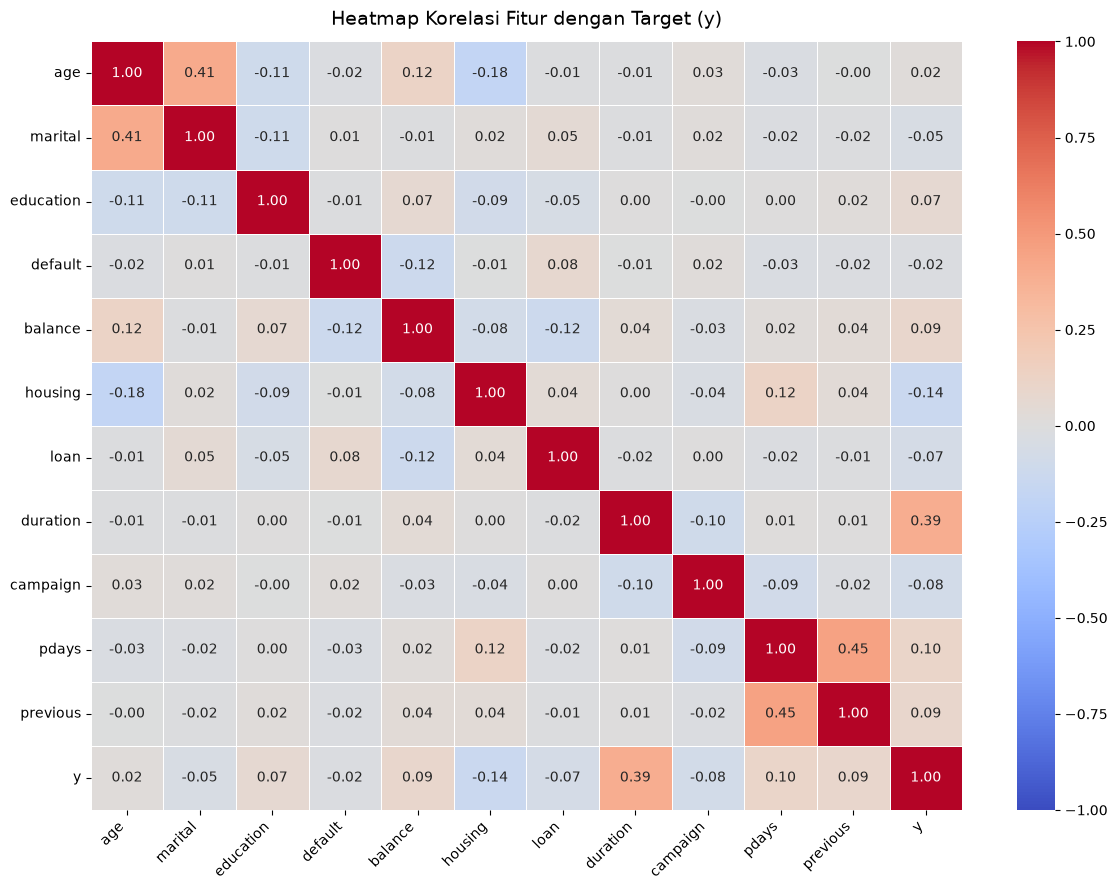

In [22]:
df_corr = X.copy()
df_corr['y'] = y

plt.figure(figsize=(12, 9))
sns.heatmap(
    df_corr.corr(), 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title('Heatmap Korelasi Fitur dengan Target (y)', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Modeling

In [23]:
def split_data (X,y,train_size = 0.8, random_state = 43):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    
    X_train , X_test = X.iloc[idx[:split_ratio]] , X.iloc[idx[split_ratio:]]
    y_train , y_test = y.iloc[idx[:split_ratio]] , y.iloc[idx[split_ratio:]]
    
    return X_train,X_test,y_train,y_test

X_train,X_test,y_train,y_test = split_data(X,y)

In [24]:
mean = X_train.mean()
std = X_train.std().replace(0, 1.0)
X_train_s = (X_train - mean) /std
X_test_s = (X_test - mean) / std

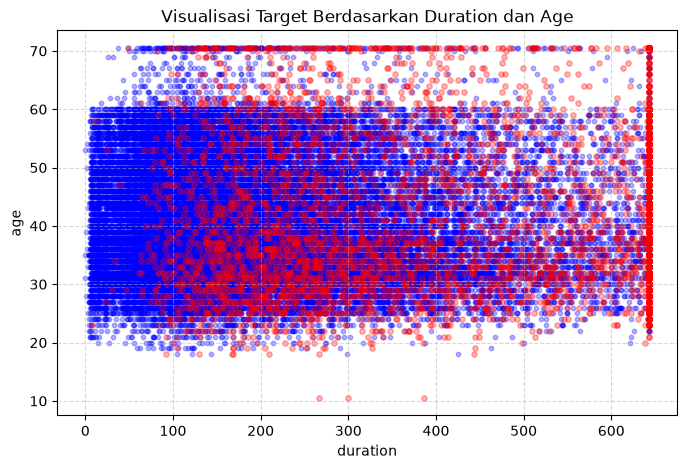

In [25]:

plt.figure(figsize=(8, 5))
plt.scatter(df[df['y'] == 'no']['duration'], df[df['y'] == 'no']['age'],color='blue',alpha=0.3, s=10)
plt.scatter(df[df['y'] == 'yes']['duration'], df[df['y'] == 'yes']['age'],color='red',alpha=0.3, s=15)
plt.title('Visualisasi Target Berdasarkan Duration dan Age')
plt.xlabel('duration')
plt.ylabel('age')

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [26]:
def euclidean (a,b):
    return np.sqrt(np.sum((a - b)**2))

In [27]:
from collections import Counter

class knn:
    def __init__ (self,k):
        self.k = k
        
    def fit (self,X,y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        
    def predict (self,X):
        X = np.array(X)
        hasil_prediksi = [self._predict(x) for x in X]
        return hasil_prediksi
    
    def _predict(self,X):
        jarak = [euclidean(X,poin) for poin in self.X_train]
        k_index = np.argsort(jarak)[:self.k]
        k_label = [self.y_train[i] for i in k_index]
        most_common = Counter(k_label).most_common(1)[0][0]
        return most_common

In [28]:
'''
knn = knn(5)
knn.fit(X_train_s,y_train)
prediksi_akhir = knn.predict(X_test_s)
akurasi = np.mean(prediksi_akhir == y_test) * 100
print(akurasi)'''

'\nknn = knn(5)\nknn.fit(X_train_s,y_train)\nprediksi_akhir = knn.predict(X_test_s)\nakurasi = np.mean(prediksi_akhir == y_test) * 100\nprint(akurasi)'

In [29]:
knn = knn(7)
knn.fit(X_train_s,y_train)
prediksi_sampel = knn.predict(X_test_s.iloc[:300].values)
akurasi = np.mean(prediksi_sampel == y_test.iloc[:300].values) * 100
print(akurasi)

89.0


## GUI Prediksi KNN (Tkinter)

Sel ini **hanya** berisi antarmuka Tkinter. Proses konversi numerik (encoding), pembersihan, split, standardisasi, dan model KNN memakai variabel yang sudah dibuat di sel-sel sebelumnya (`X`, `df`, `mean`, `std`, `knn`), jadi tidak ditulis ulang.

> Jalankan sel-sel di atas terlebih dahulu, baru jalankan sel di bawah untuk membuka jendela aplikasi.

- **Isi Otomatis** : mengisi form dari sampel acak dataset
- **Contoh: Berpotensi Pelanggan** : contoh nasabah yang diprediksi berlangganan
- **Contoh: Tidak Berpotensi** : contoh nasabah yang diprediksi tidak berlangganan


In [30]:
# ============================================================
# GUI Tkinter: Prediksi Nasabah Bank Marketing
# HANYA berisi UI. Semua preprocessing, encoding, split, standardisasi,
# dan model KNN memakai variabel yang sudah dibuat di sel-sel sebelumnya:
#   - X      : DataFrame fitur (sudah di-encode & di-clip)
#   - df     : DataFrame data (untuk contoh nasabah)
#   - mean, std : hasil standardisasi dari X_train
#   - knn    : model KNN yang sudah di-fit
# Jalankan sel-sel di atas terlebih dahulu.
# ============================================================
import tkinter as tk
from tkinter import ttk, messagebox

import numpy as np

# Label kategori untuk form (nilai angkanya sesuai encoding di sel sebelumnya)
MARITAL = {"single": 0, "married": 1, "divorced": 2}
EDUCATION = {"primary": 0, "secondary": 1, "tertiary": 2, "unknown": 3}
BINARY = {"no": 0, "yes": 1}
INV_MARITAL = {v: k for k, v in MARITAL.items()}
INV_EDUCATION = {v: k for k, v in EDUCATION.items()}
INV_BINARY = {v: k for k, v in BINARY.items()}

COLUMNS = X.columns.tolist()
NUM_FIELDS = ["age", "balance", "duration", "campaign", "pdays", "previous"]

# akurasi model yang sudah dilatih (pakai X_test_s & y_test dari sel sebelumnya)
AKURASI = np.mean(
    [knn._predict(r) for r in X_test_s.iloc[:300].values] == y_test.iloc[:300].values
) * 100


def _prediksi(nilai):
    """Terima dict {kolom: angka}, kembalikan label 0/1 memakai model knn."""
    v = np.array([nilai[c] for c in COLUMNS], dtype=float)
    return knn._predict((v - mean.values) / std.values)


def _cari_contoh(target):
    """Cari 1 baris nyata yang diprediksi `target` (1=ya, 0=tidak)."""
    kandidat = df[df["y"] == ("yes" if target == 1 else "no")].sample(n=300, random_state=1)
    for _, baris in kandidat.iterrows():
        if _prediksi({c: float(baris[c]) for c in COLUMNS}) == target:
            return baris
    return None


CONTOH_YA = _cari_contoh(1)
CONTOH_TIDAK = _cari_contoh(0)


class PrediksiKNN(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title("Prediksi KNN - Bank Marketing")
        self.geometry("560x780")
        self.resizable(False, False)
        self._build_ui()

    def _build_ui(self):
        header = tk.Frame(self, bg="#1f4e79", height=70)
        header.pack(fill="x")
        tk.Label(header, text="Prediksi Nasabah Berlangganan", bg="#1f4e79",
                 fg="white", font=("Segoe UI", 15, "bold")).pack(pady=(12, 0))
        tk.Label(header, text="Metode K-Nearest Neighbors (KNN)", bg="#1f4e79",
                 fg="#cfe2f3", font=("Segoe UI", 10)).pack(pady=(0, 12))

        form = ttk.Frame(self, padding=20)
        form.pack(fill="both", expand=True)
        form.columnconfigure(1, weight=1)

        self.entries, self.combos = {}, {}
        rows = {
            "age": ("entry", "Umur", "35"),
            "marital": ("combo", "Status Pernikahan", list(MARITAL.keys())),
            "education": ("combo", "Pendidikan", list(EDUCATION.keys())),
            "default": ("combo", "Kredit Gagal (default)", list(BINARY.keys())),
            "balance": ("entry", "Saldo (balance)", "1000"),
            "housing": ("combo", "Kredit Rumah (housing)", list(BINARY.keys())),
            "loan": ("combo", "Pinjaman (loan)", list(BINARY.keys())),
            "duration": ("entry", "Durasi Telepon (duration)", "300"),
            "campaign": ("entry", "Jumlah Kontak (campaign)", "2"),
            "pdays": ("entry", "Hari Sejak Kontak Terakhir (pdays)", "-1"),
            "previous": ("entry", "Kontak Sebelumnya (previous)", "0"),
        }

        r = 0
        for col, (kind, label, val) in rows.items():
            ttk.Label(form, text=label, font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", pady=5, padx=(0, 10))
            if kind == "entry":
                e = ttk.Entry(form, font=("Segoe UI", 10))
                e.insert(0, val)
                e.grid(row=r, column=1, sticky="ew", pady=5)
                self.entries[col] = e
            else:
                c = ttk.Combobox(form, values=val, state="readonly", font=("Segoe UI", 10))
                c.current(0)
                c.grid(row=r, column=1, sticky="ew", pady=5)
                self.combos[col] = c
            r += 1

        # baris tombol 1: isi data & aksi
        btns = ttk.Frame(form)
        btns.grid(row=r, column=0, columnspan=2, sticky="ew", pady=(16, 4))
        btns.columnconfigure((0, 1, 2), weight=1)
        ttk.Button(btns, text="Isi Otomatis", command=self.on_autofill).grid(
            row=0, column=0, sticky="ew", padx=(0, 5), ipady=6)
        ttk.Button(btns, text="Prediksi", command=self.on_predict).grid(
            row=0, column=1, sticky="ew", padx=5, ipady=6)
        ttk.Button(btns, text="Reset", command=self.on_reset).grid(
            row=0, column=2, sticky="ew", padx=(5, 0), ipady=6)

        # baris tombol 2: contoh nasabah berpotensi / tidak berpotensi
        btns2 = ttk.Frame(form)
        btns2.grid(row=r + 1, column=0, columnspan=2, sticky="ew", pady=(0, 6))
        btns2.columnconfigure((0, 1), weight=1)
        ttk.Button(btns2, text="Contoh: Berpotensi Pelanggan",
                   command=self.on_contoh_ya).grid(
            row=0, column=0, sticky="ew", padx=(0, 5), ipady=6)
        ttk.Button(btns2, text="Contoh: Tidak Berpotensi",
                   command=self.on_contoh_tidak).grid(
            row=0, column=1, sticky="ew", padx=(5, 0), ipady=6)

        self.result_var = tk.StringVar(value="Masukkan data lalu tekan Prediksi.")
        self.result_label = tk.Label(form, textvariable=self.result_var,
                                     font=("Segoe UI", 12, "bold"), bg="#f2f2f2",
                                     fg="#333333", wraplength=480, justify="center", pady=16)
        self.result_label.grid(row=r + 2, column=0, columnspan=2, sticky="ew", pady=(8, 0))

        tk.Label(self, text=f"Model siap - akurasi uji 300 sampel {AKURASI:.2f}%",
                 font=("Segoe UI", 9), fg="#666666").pack(side="bottom", pady=6)

    # ---------------------- aksi tombol ----------------------
    def _kumpulkan_input(self):
        nilai = {}
        for col, entry in self.entries.items():
            teks = entry.get().strip().replace(",", ".")
            if teks == "":
                raise ValueError(f"Field '{col}' tidak boleh kosong.")
            try:
                nilai[col] = float(teks)
            except ValueError:
                raise ValueError(f"Field '{col}' harus berupa angka.")
        for col, combo in self.combos.items():
            pilih = combo.get()
            nilai[col] = MARITAL[pilih] if col == "marital" else (
                EDUCATION[pilih] if col == "education" else BINARY[pilih])
        return nilai

    def _isi_form(self, baris):
        for col, entry in self.entries.items():
            entry.delete(0, tk.END)
            v = float(baris[col])
            entry.insert(0, str(int(v)) if v.is_integer() else str(v))
        self.combos["marital"].set(INV_MARITAL[int(baris["marital"])])
        self.combos["education"].set(INV_EDUCATION[int(baris["education"])])
        self.combos["default"].set(INV_BINARY[int(baris["default"])])
        self.combos["housing"].set(INV_BINARY[int(baris["housing"])])
        self.combos["loan"].set(INV_BINARY[int(baris["loan"])])

    def _tampilkan_hasil(self):
        label = _prediksi(self._kumpulkan_input())
        if label == 1:
            self.result_var.set("PREDIKSI: YA - nasabah berpotensi berlangganan")
            self.result_label.configure(bg="#d9ead3", fg="#1e6b34")
        else:
            self.result_var.set("PREDIKSI: TIDAK - nasabah kemungkinan tidak berlangganan")
            self.result_label.configure(bg="#fce5cd", fg="#a3441c")

    def on_autofill(self):
        self._isi_form(df.sample(n=1).iloc[0])
        self.result_var.set("Data contoh terisi otomatis. Tekan Prediksi untuk melihat hasil.")
        self.result_label.configure(bg="#f2f2f2", fg="#333333")

    def on_contoh_ya(self):
        if CONTOH_YA is None:
            messagebox.showwarning("Info", "Tidak menemukan contoh nasabah berpotensi.")
            return
        self._isi_form(CONTOH_YA)
        self._tampilkan_hasil()

    def on_contoh_tidak(self):
        if CONTOH_TIDAK is None:
            messagebox.showwarning("Info", "Tidak menemukan contoh nasabah tidak berpotensi.")
            return
        self._isi_form(CONTOH_TIDAK)
        self._tampilkan_hasil()

    def on_predict(self):
        try:
            self._tampilkan_hasil()
        except ValueError as exc:
            messagebox.showwarning("Input tidak valid", str(exc))

    def on_reset(self):
        default = {"age": "35", "balance": "1000", "duration": "300",
                   "campaign": "2", "pdays": "-1", "previous": "0"}
        for col, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, default.get(col, "0"))
        for combo in self.combos.values():
            combo.current(0)
        self.result_var.set("Masukkan data lalu tekan Prediksi.")
        self.result_label.configure(bg="#f2f2f2", fg="#333333")


# ---- jalankan aplikasi ----
app = PrediksiKNN()
app.mainloop()
